In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

In [2]:
%pip install s3fs
import s3fs

fs=s3fs.S3FileSystem(client_kwargs={"endpoint_url":"https://minio.lab.sspcloud.fr"})
MY_BUCKET = "mgibault"
print(fs.ls(MY_BUCKET))


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
['mgibault/DS_RP_EMPLOI_LR_COMP_2023_data.csv', 'mgibault/fr-en-indicateurs-de-resultat-des-lycees-denseignement-general-et-technologique (1).csv']


In [18]:
with fs.open(f"{MY_BUCKET}/DS_RP_EMPLOI_LR_COMP_2023_data.csv","rb")as f:
    emploi= pd.read_csv(f,sep=";",dtype={"GEO": str,"EMPSTA_ENQ":str})
    emploi = emploi [['TIME_PERIOD','EMPSTA_ENQ','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["PCS"] == "_T"] # on choisit de s'intéresser aux résultats agrégés par PCS.
# Si on veut une analyse plus fine, on pourra dans un second temps regarder par PCS...
emploi_dep = emploi_dep.reset_index(drop=True)
emploi_dep = emploi_dep.rename(columns={
    "TIME_PERIOD": "Annee",
    "EMPSTA_ENQ":"Statut",
    "GEO":"Code departement",
    "OBS_VALUE": "Population"
})

emploi_dep= emploi_dep.drop(columns=["PCS"])

emploi_dep.head(20)

,Annee,Statut,Code departement,Population
0,2012,1,001,5.684150e+06
1,2012,1T2,001,6.377119e+06
2,2012,2,001,6.929694e+05
3,2017,1,001,5.696479e+06
4,2017,1T2,001,6.407343e+06
5,2017,2,001,7.108635e+05
6,2023,1,001,5.997447e+06
7,2023,1T2,001,6.598552e+06
8,2023,2,001,6.011057e+05
9,2012,1,002,9.094996e+05


In [19]:
emploi_pivot = emploi_dep[emploi_dep['Code departement'].str.len() == 3]
emploi_pivot= emploi_pivot.pivot_table(
    index=['Annee', 'Code departement'],
    columns='Statut',
    values='Population').reset_index()

emploi_pivot.head(20)


Statut,Annee,Code departement,1,1T2,2
0,2012,001,5.684150e+06,6.377119e+06,692969.389410
1,2012,002,9.094996e+05,1.021020e+06,111520.659150
2,2012,003,6.850123e+05,7.922593e+05,107246.977690
3,2012,004,5.828589e+05,6.732480e+05,90389.106180
4,2012,005,5.833271e+05,6.553992e+05,72072.172470
5,2012,006,5.238807e+05,5.903065e+05,66425.825870
6,2012,008,4.030589e+05,4.481345e+05,45075.620400
7,2012,010,3.502405e+05,3.941662e+05,43925.765410
8,2012,011,5.005247e+04,5.536768e+04,5315.215620
9,2012,012,2.117370e+05,2.419748e+05,30237.769915


In [20]:
emploi_pivot["Taux d'activite"]=emploi_pivot["1"]/emploi_pivot['1T2']
emploi_pivot=emploi_pivot.drop(columns=["1","1T2","2"])
emploi_pivot.head()

Statut,Annee,Code departement,Taux d'activite
0,2012,001,0.891335
1,2012,002,0.890775
2,2012,003,0.864631
3,2012,004,0.865742
4,2012,005,0.890033


In [24]:
# base avec un taux de progression entre 2017 et 2023 du taux d'activité par département

emploi_prog_CT=emploi_pivot[["Code departement","Annee","Taux d'activite"]]
emploi_prog_CT=emploi_prog_CT[(emploi_prog_CT["Annee"]==2017)| (emploi_prog_CT["Annee"]==2023)]

emploi_prog_CT=emploi_prog_CT.pivot_table(
    index=['Code departement'],
    columns='Annee',
    values="Taux d'activite").reset_index()

emploi_prog_CT["Progression 2016"]=emploi_prog_CT[2023]-emploi_prog_CT[2017]

emploi_prog_CT.head(15)

Annee,Code departement,2017,2023,Progression 2016
0,001,0.889055,0.908903,0.019849
1,002,0.890444,0.914784,0.024340
2,003,0.867962,0.906470,0.038509
3,004,0.861590,0.895545,0.033955
4,005,0.885475,0.910001,0.024526
5,006,0.880970,0.914439,0.033469
6,008,0.896621,0.923513,0.026892
7,010,0.885235,0.910268,0.025033
8,011,0.899181,0.925007,0.025826
9,012,0.872169,0.897273,0.025104


Préparation des données du bac à partir de ce site: 

In [7]:
with fs.open('mgibault/fr-en-indicateurs-de-resultat-des-lycees-denseignement-general-et-technologique (1).csv',"rb")as bac_f:
    bac= pd.read_csv(bac_f,sep=";")
bac.head()

/tmp/ipykernel_40340/3095888097.py:2: DtypeWarning: Columns (47: Taux de reussite attendu france - L, 48: Taux de reussite attendu france - ES, 49: Taux de reussite attendu france - S, 51: Taux de reussite attendu france - STI2D, 52: Taux de reussite attendu france - STD2A, 53: Taux de reussite attendu france - STMG, 55: Taux de reussite attendu france - STL, 56: Taux de reussite attendu france - ST2S, 57: Taux de reussite attendu france - TMD, 58: Taux de reussite attendu france - STHR, 59: Taux de reussite attendu france - Toutes series, 71: Taux de mentions attendu - L, 72: Taux de mentions attendu - ES, 73: Taux de mentions attendu - S, 74: Taux de mentions attendu - STI2D, 75: Taux de mentions attendu - STD2A, 76: Taux de mentions attendu - STMG, 77: Taux de mentions attendu - STL, 78: Taux de mentions attendu - ST2S, 79: Taux de mentions attendu - TMD, 80: Taux de mentions attendu - STHR, 81: Taux de mentions attendu - Toutes series, 83: Structure pedagogique 7 groupes, 95: Taux 

,Etablissement,Annee,Ville,UAI,Code commune,Academie,Departement,Secteur,Presents - L,Presents - ES,...,Valeur ajoutée du taux de mentions - Gnle,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T,Libelle departement
0,LYCEE VICTOR BERARD (GENERAL ET TECHNO.),2023,MOREZ,0390027T,39368,BESANCON,JURA,public,NaN,NaN,...,-3,1.0,8.0,24.0,29.0,NaN,NaN,10.0,7.0,Jura
1,LYCEE VAL DE LOIRE (GENERAL ET TECHNO.),2023,BLOIS,0410899E,41018,ORLEANS-TOURS,LOIR-ET-CHER,public,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.0,5.0,15.0,Loir-et-Cher
2,LYCEE JACOB HOLTZER,2023,FIRMINY,0420014M,42095,LYON,LOIRE,public,NaN,NaN,...,-17,NaN,6.0,10.0,19.0,NaN,NaN,1.0,8.0,Loire
3,LYCEE HONORE D'URFE,2023,SAINT ETIENNE,0420042T,42218,LYON,LOIRE,public,NaN,NaN,...,1,1.0,16.0,53.0,63.0,NaN,NaN,21.0,37.0,Loire
4,LYCEE JEAN MONNET,2023,SAINT ETIENNE,0420043U,42218,LYON,LOIRE,public,NaN,NaN,...,-5,NaN,8.0,10.0,31.0,NaN,NaN,10.0,20.0,Loire


In [13]:
bac=bac[["Annee","Code departement",
"Presents - Toutes series",
"Presents - Gnle",
"Taux de reussite - Toutes series",
"Taux de mentions - Toutes series",
"Taux de reussite - Gnle",
"Taux de mentions - Gnle"]]

bac.head(10)

,Annee,Code departement,Presents - Toutes series,Presents - Gnle,Taux de reussite - Toutes series,Taux de mentions - Toutes series,Taux de reussite - Gnle,Taux de mentions - Gnle
0,2023,39,120,95.0,98.0,66.0,97.0,65.0
1,2023,41,38,NaN,95.0,61.0,NaN,NaN
2,2023,42,99,69.0,96.0,44.0,96.0,51.0
3,2023,42,415,235.0,89.0,46.0,94.0,57.0
4,2023,42,160,96.0,92.0,49.0,92.0,51.0
5,2023,42,67,48.0,96.0,52.0,96.0,54.0
6,2023,43,135,114.0,96.0,63.0,96.0,63.0
7,2023,43,55,55.0,98.0,47.0,98.0,47.0
8,2023,44,271,271.0,99.0,77.0,99.0,77.0
9,2023,44,106,NaN,100.0,66.0,NaN,NaN


L'idée est donc de créer 2 df pour regarder ce qui est le plus pertinent: le général ou le total.

In [14]:
bac_tot=bac[["Annee","Code departement","Presents - Toutes series","Taux de reussite - Toutes series","Taux de mentions - Toutes series"]]

bac_tot["reussites_poids"] = bac_tot["Presents - Toutes series"]*bac_tot["Taux de reussite - Toutes series"]/100
bac_tot["mentions_poids"] = bac_tot["Presents - Toutes series"]*bac_tot["Taux de mentions - Toutes series"]/100
bac_tot=bac_tot[(bac_tot["Annee"]==2012) | (bac_tot["Annee"]==2016) | (bac_tot["Annee"]==2022)|(bac_tot["Annee"]==2017) | (bac_tot["Annee"]==2023)]


bac_tot = bac_tot.groupby(["Code departement","Annee"]).agg({"Presents - Toutes series":"sum",
                                               "reussites_poids":"sum",
                                               "mentions_poids":"sum"})

bac_tot["Taux de reussite"] = bac_tot["reussites_poids"]/bac_tot["Presents - Toutes series"]
bac_tot["Taux de mentions"] = bac_tot["mentions_poids"]/bac_tot["Presents - Toutes series"]
bac_tot=bac_tot.reset_index()

bac_tot.head(20)

,Code departement,Annee,Presents - Toutes series,reussites_poids,mentions_poids,Taux de reussite,Taux de mentions
0,01,2012,3628,3321.34,0.00,0.915474,0.000000
1,01,2016,4035,3725.29,0.00,0.923244,0.000000
2,01,2017,4208,3806.90,2086.12,0.904682,0.495751
3,01,2022,4550,4305.94,2802.65,0.946360,0.615967
4,01,2023,4713,4467.15,2858.18,0.947836,0.606446
5,02,2012,3374,2826.09,0.00,0.837608,0.000000
6,02,2016,3366,3032.52,0.00,0.900927,0.000000
7,02,2017,3545,3181.16,1612.08,0.897365,0.454748
8,02,2022,3425,3190.01,2009.09,0.931390,0.586596
9,02,2023,3388,3164.39,1853.15,0.933999,0.546975


On utilise les données de 2016 et 2022 (et non pas 2017 et 2023 comme pour le chômage) car l'espérance de scolarisation à 2 ans était de 18,6 ans en 2019 (arrondi ici à 1 an, donc 19 ans). Cf https://www.education.gouv.fr/sites/default/files/document/NI%2022.05-312021.pdf

In [10]:
# base avec un taux de progression entre 2017 et 2023

bac_prog_CT=bac_tot[["Code departement","Annee","Taux de reussite"]]
bac_prog_CT=bac_prog_CT[(bac_prog_CT["Annee"]==2016)| (bac_prog_CT["Annee"]==2022)]

bac_prog_CT=bac_prog_CT.pivot_table(
    index=['Code departement'],
    columns='Annee',
    values='Taux de reussite').reset_index()

bac_prog_CT["Progression 2016"]=bac_prog_CT[2022]-bac_prog_CT[2016]

bac_prog_CT.head(15)

Annee,Code departement,2016,2022,Progression 2016
0,01,0.923244,0.946360,0.023116
1,02,0.900927,0.931390,0.030463
2,03,0.923779,0.942115,0.018336
3,04,0.925481,0.954701,0.029220
4,05,0.955525,0.977633,0.022108
5,06,0.925766,0.941507,0.015740
6,07,0.924004,0.963484,0.039480
7,08,0.903466,0.900838,-0.002628
8,09,0.896208,0.965503,0.069294
9,10,0.916014,0.931404,0.015390


In [25]:
emploi_prog_CT["Code departement"] = emploi_prog_CT["Code departement"].astype(str).str.zfill(3)

bac_prog_CT["Code departement"] = bac_prog_CT["Code departement"].astype(str).str.zfill(3)

bac_emploi_prog_CT = bac_prog_CT.merge(
    emploi_prog_CT,
    left_on = ["Code departement"],
  right_on = ["Code departement"],
  how = "left"
)



bac_emploi_prog_CT = bac_emploi_prog_CT.dropna()

bac_emploi_prog_CT.head(15)

Annee,Code departement,2016,2022,Progression 2016_x,2017,2023,Progression 2016_y
0,001,0.923244,0.946360,0.023116,0.889055,0.908903,0.019849
1,002,0.900927,0.931390,0.030463,0.890444,0.914784,0.024340
2,003,0.923779,0.942115,0.018336,0.867962,0.906470,0.038509
3,004,0.925481,0.954701,0.029220,0.861590,0.895545,0.033955
4,005,0.955525,0.977633,0.022108,0.885475,0.910001,0.024526
5,006,0.925766,0.941507,0.015740,0.880970,0.914439,0.033469
7,008,0.903466,0.900838,-0.002628,0.896621,0.923513,0.026892
9,010,0.916014,0.931404,0.015390,0.885235,0.910268,0.025033
10,011,0.919766,0.939042,0.019276,0.899181,0.925007,0.025826
11,012,0.953416,0.980768,0.027352,0.872169,0.897273,0.025104


Text(0.5, 1.0, "Comparaison de la progression des taux d'activité et de réussite au baccalauréat par département entre 2016 et 2023")

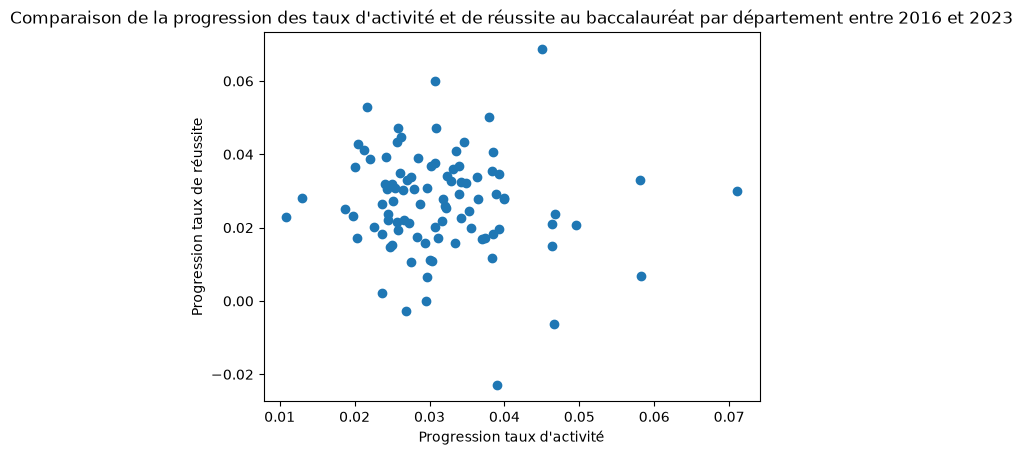

In [12]:
plt.scatter(bac_emploi_prog_CT["Progression 2016_y"],bac_emploi_prog_CT["Progression 2016_x"])
plt.xlabel("Progression taux d'activité")
plt.ylabel("Progression taux de réussite")
plt.title("Comparaison de la progression des taux d'activité et de réussite au baccalauréat par département entre 2016 et 2023")

conclusion: ce n'est pas très concluant...

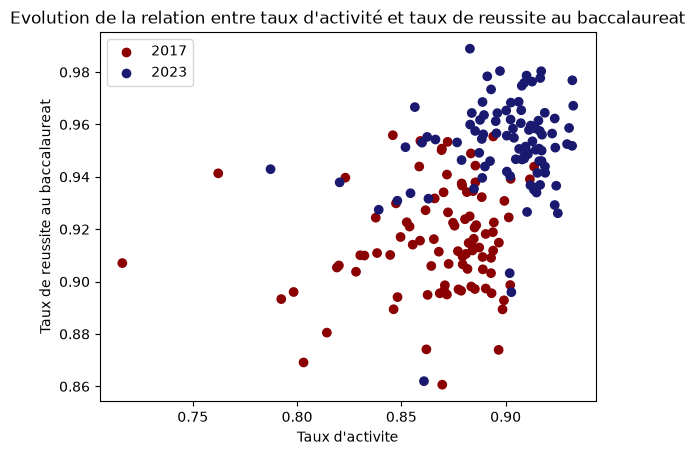

In [45]:
couleurs= {'2017':'darkred', '2023':'midnightblue'}

emploi_filtre = emploi_pivot[emploi_pivot["Annee"].isin([2017, 2023])]
bac_filtre = bac_tot[bac_tot["Annee"].isin([2017, 2023])]

emploi_filtre["Code departement"] = emploi_filtre["Code departement"].astype(str).str.zfill(3)
bac_filtre["Code departement"] = bac_filtre["Code departement"].astype(str).str.zfill(3)

bac_emploi_filtre = emploi_filtre.merge(
    bac_filtre,
    on=["Annee","Code departement"],
    how="inner"
)

plt.scatter(bac_emploi_filtre["Taux d'activite"],
    bac_emploi_filtre["Taux de reussite"],
    c=bac_emploi_filtre["Annee"].astype(str).map(couleurs)
)

plt.xlabel("Taux d'activite")
plt.ylabel("Taux de reussite au baccalaureat")
plt.scatter([], [], color='darkred', label='2017')
plt.scatter([], [], color='midnightblue', label='2023')

plt.legend()

plt.title("Evolution de la relation entre taux d'activité et taux de reussite au baccalaureat")

plt.show()


On veut désormais faire un graphique avec des flèches pour rendre plus lisible les évolutions

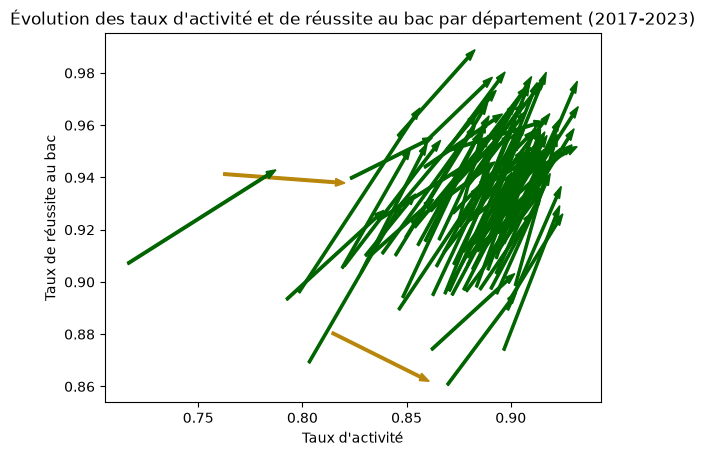

In [53]:
bac_emploi_dep=bac_emploi_filtre.pivot(
    index="Code departement",
    columns="Annee",
    values=["Taux d'activite", "Taux de reussite"]
)

for departement in bac_emploi_dep.index:

    x1 = bac_emploi_dep.loc[departement, ("Taux d'activite", 2017)]
    y1 = bac_emploi_dep.loc[departement, ("Taux de reussite", 2017)]

    x2 = bac_emploi_dep.loc[departement, ("Taux d'activite", 2023)]
    y2 = bac_emploi_dep.loc[departement, ("Taux de reussite", 2023)]

    if x2>x1 and y2>y1:
        couleur="darkgreen"
    
    elif x1>x2 and y1>y2:
        couleur="darkred"
    
    else:
        couleur="darkgoldenrod"

    plt.arrow(
        x1, y1,
        x2-x1, y2-y1,
        color=couleur,
        length_includes_head=True
    )

plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite au bac")
plt.title("Évolution des taux d'activité et de réussite au bac par département (2017-2023)")

plt.show()